# Auto-Rickshaw Fare Distribution Analysis
## Seaborn Session 3 – Distribution Plots

Analysis of 500 fictional auto-rickshaw trips using histograms and kernel density estimation (KDE).

Task 1: Generate 500 auto-rickshaw trips

   trip_id time_slot  distance_km    fare_inr
0        1     Night         20.2  340.615089
1        2   Morning          3.6   94.266520
2        3     Night          4.3  132.464660
3        4     Night          6.3  169.619510
4        5   Morning          1.3   16.606667
Total Trips: 500


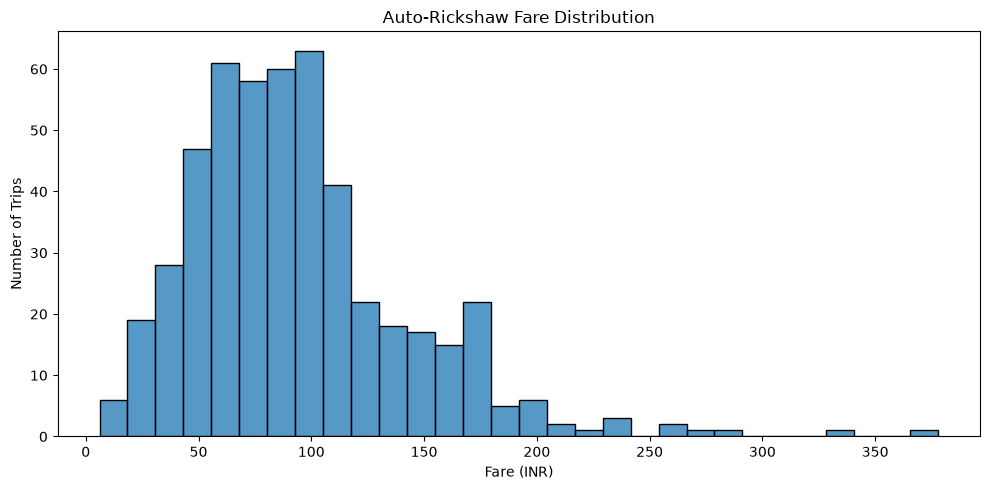

In [1]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

np.random.seed(42)

trip_id = np.arange(1, 501)

time_slot = np.random.choice(
    ["Morning", "Afternoon", "Night"],
    size=500
)

distance_km = np.random.gamma(
    shape=2,
    scale=2,
    size=500
)

distance_km = np.clip(distance_km, 0.5, 25)
distance_km = np.round(distance_km, 1)

noise = np.random.normal(0, 15, 500)

fare_inr = 30 + 13 * distance_km + noise

fare_inr = np.where(
    time_slot == "Night",
    fare_inr * 1.25,
    fare_inr
)

df = pd.DataFrame({
    "trip_id": trip_id,
    "time_slot": time_slot,
    "distance_km": distance_km,
    "fare_inr": fare_inr
})

df.to_csv("rickshaw_trips.csv", index=False)

print(df.head())
print("Total Trips:", len(df))

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="fare_inr",
    bins=30
)

plt.title("Auto-Rickshaw Fare Distribution")
plt.xlabel("Fare (INR)")
plt.ylabel("Number of Trips")

plt.tight_layout()
plt.show()


Task 2: Compare KDE bandwidths

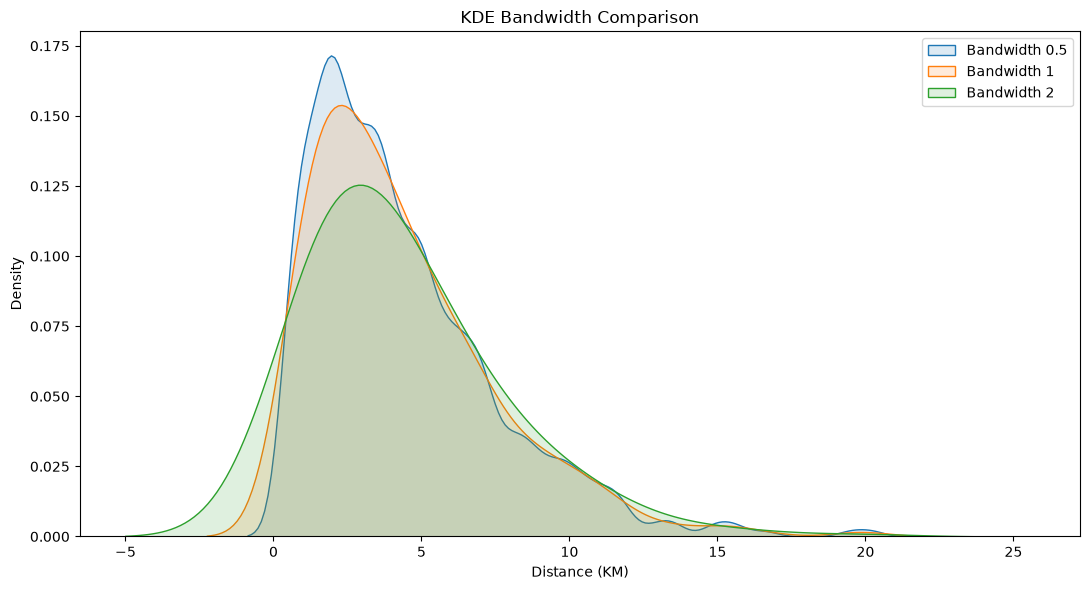

Bandwidth chart saved!


In [2]:

fig, ax = plt.subplots(figsize=(11, 6))

for bw in [0.5, 1, 2]:
    sns.kdeplot(
        data=df,
        x="distance_km",
        bw_adjust=bw,
        fill=True,
        alpha=0.15,
        label=f"Bandwidth {bw}",
        ax=ax
    )

ax.set_title("KDE Bandwidth Comparison")
ax.set_xlabel("Distance (KM)")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.savefig("rickshaw_bandwidth.png", dpi=150)
plt.show()

print("Bandwidth chart saved!")


Task 3: Histogram and KDE comparison

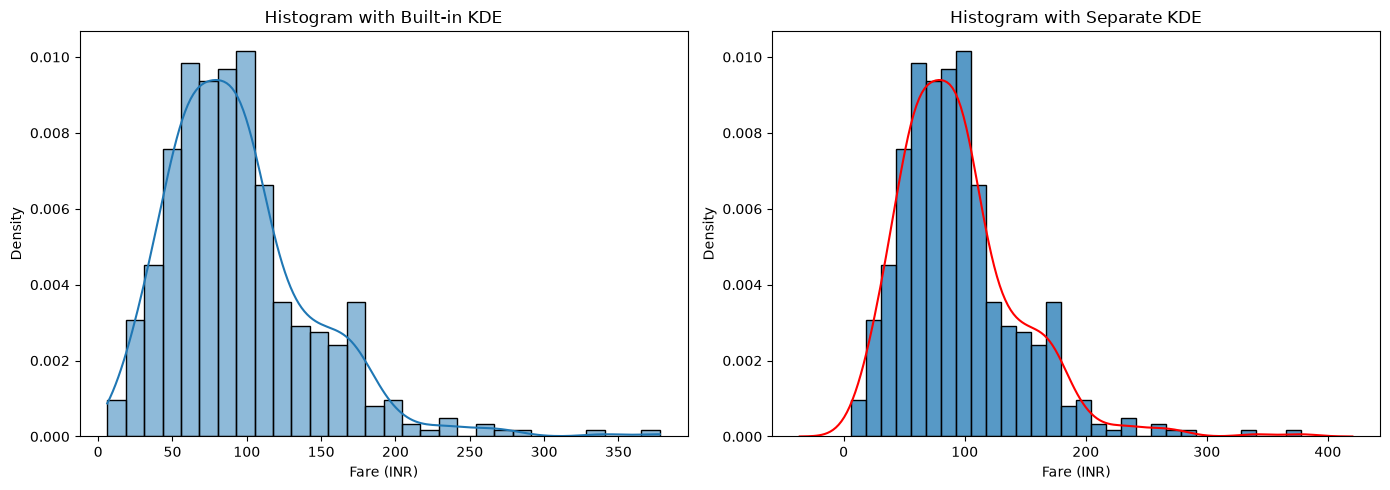

Histogram and KDE comparison saved!


In [3]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Histogram with built-in KDE
sns.histplot(
    data=df,
    x="fare_inr",
    bins=30,
    stat="density",
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Histogram with Built-in KDE")
axes[0].set_xlabel("Fare (INR)")
axes[0].set_ylabel("Density")

# Right: Histogram and separate KDE
sns.histplot(
    data=df,
    x="fare_inr",
    bins=30,
    stat="density",
    ax=axes[1]
)

sns.kdeplot(
    data=df,
    x="fare_inr",
    ax=axes[1],
    color="red"
)

axes[1].set_title("Histogram with Separate KDE")
axes[1].set_xlabel("Fare (INR)")
axes[1].set_ylabel("Density")

plt.tight_layout()
plt.savefig("rickshaw_hist_kde.png", dpi=150)
plt.show()

print("Histogram and KDE comparison saved!")


Task 4: Final fare distribution report

Median Fares:
time_slot
Afternoon    84.334655
Morning      77.541632
Night        99.905593
Name: fare_inr, dtype: float64


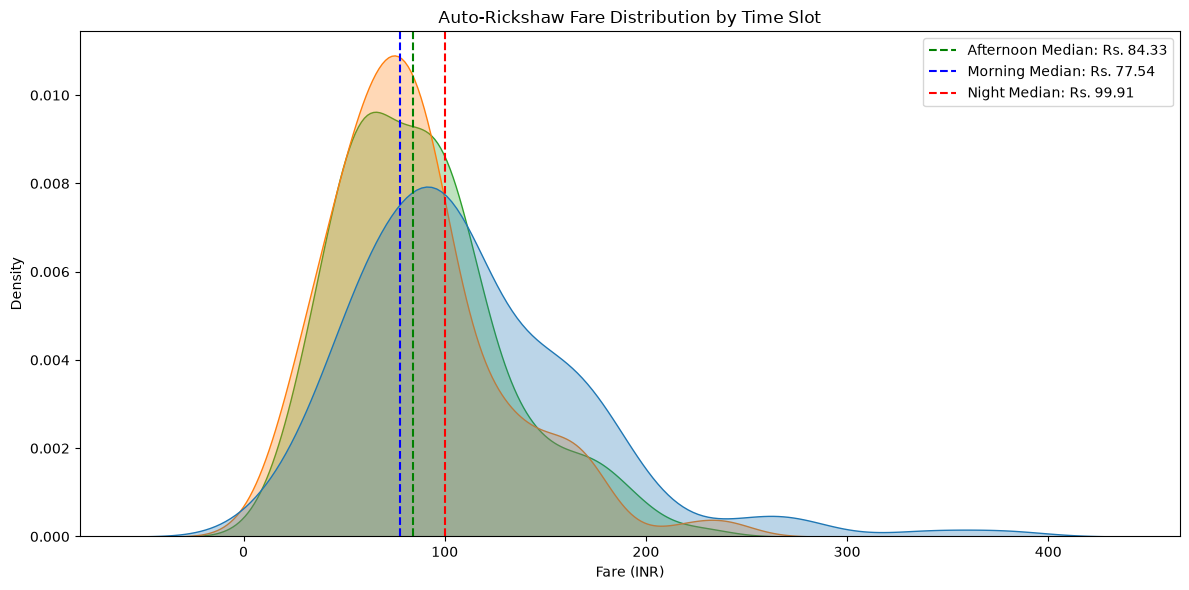

Final report saved successfully!


In [4]:

fig, ax = plt.subplots(figsize=(12, 6))

sns.kdeplot(
    data=df,
    x="fare_inr",
    hue="time_slot",
    fill=True,
    common_norm=False,
    alpha=0.3,
    ax=ax
)

# Median fare for each time slot
medians = df.groupby("time_slot")["fare_inr"].median()

colors = {
    "Morning": "blue",
    "Afternoon": "green",
    "Night": "red"
}

for slot, median in medians.items():
    ax.axvline(
        x=median,
        color=colors[slot],
        linestyle="--",
        label=f"{slot} Median: Rs. {median:.2f}"
    )

print("Median Fares:")
print(medians)

ax.set_title("Auto-Rickshaw Fare Distribution by Time Slot")
ax.set_xlabel("Fare (INR)")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()
plt.savefig("rickshaw_fare_report.png", dpi=150)
plt.show()

print("Final report saved successfully!")
